# Spam Detector — Predictive Analytics Mini Project

**Goal:** classify an SMS message as **ham** (legitimate) or **spam** using TF-IDF features and Logistic Regression.

**Dataset:** UCI SMS Spam Collection. The original corpus has 5,572 labelled records. Exact duplicate rows are removed for this project, leaving 5,158 unique messages.

This notebook follows a reproducible 80:20 stratified train/test split. It reports measured performance; it does not force a target accuracy.

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
import joblib
from pathlib import Path

DATA_PATH = Path("spam.csv")
df = pd.read_csv(DATA_PATH)
df = df[["label", "message"]].dropna()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""].drop_duplicates().reset_index(drop=True)

print("Dataset shape:", df.shape)
print(df["label"].value_counts())
df.head()

Dataset shape: (5158, 2)
label
ham     4016
spam     1142
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 2. Exploratory Data Analysis
We inspect class balance and message length. Spam is the minority class, so we use stratified splitting and balanced class weights.

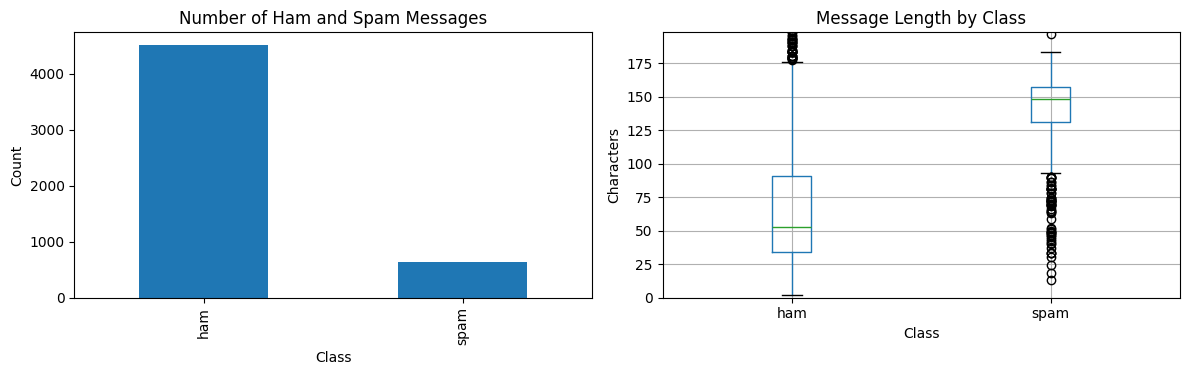

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4516.0,70.869575,56.708714,2.0,34.0,53.0,91.0,910.0
spam,642.0,137.408100,29.977971,13.0,131.0,148.0,157.0,223.0


In [2]:
df["message_length"] = df["message"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["label"].value_counts().reindex(["ham", "spam"]).plot(kind="bar", ax=axes[0])
axes[0].set_title("Number of Ham and Spam Messages")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")
df.boxplot(column="message_length", by="label", ax=axes[1])
axes[1].set_title("Message Length by Class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Characters")
axes[1].set_ylim(0, df["message_length"].quantile(0.98))
plt.suptitle("")
plt.tight_layout()
plt.show()

df.groupby("label")["message_length"].describe()

## 3. Prepare training and testing data

- `ham` is encoded as 0 and `spam` as 1.
- 80% of the data is used for training and 20% for testing.
- `stratify=y` preserves the class proportions in both subsets.

In [3]:
X = df["message"]
y = df["label"].map({"ham": 0, "spam": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training messages: {len(X_train)}")
print(f"Testing messages: {len(X_test)}")
print("Spam proportion — train:", round(y_train.mean(), 3),
      "| test:", round(y_test.mean(), 3))

Training messages: 4126
Testing messages: 1032
Spam proportion — train: 0.125 | test: 0.124


## 4. Build and train the model

TF-IDF gives numerical weights to informative terms. Unigrams and bigrams capture single words and short phrases. Logistic Regression learns a binary classifier.

To address class imbalance, we apply random oversampling to the training split only: spam messages are randomly duplicated until ham and spam counts are equal. The test set remains unchanged to avoid leakage and to evaluate on the original distribution.

The TF-IDF vectorizer and classifier are kept together in a Pipeline so the app applies the same preprocessing at prediction time.

In [ ]:
# Random oversampling on training data only
train_df = pd.DataFrame({"message": X_train, "label": y_train})
ham_train = train_df[train_df["label"] == 0]
spam_train = train_df[train_df["label"] == 1]
spam_oversampled = spam_train.sample(n=len(ham_train), replace=True, random_state=42)
balanced_train = pd.concat([ham_train, spam_oversampled]).sample(frac=1, random_state=42)
X_train_balanced = balanced_train["message"]
y_train_balanced = balanced_train["label"]
print("Balanced training counts:", y_train_balanced.value_counts())

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

model.fit(X_train_balanced, y_train_balanced)
print("Training complete.")

## 5. Evaluate on the held-out test set
Accuracy alone can hide minority-class errors. We therefore also report spam precision, spam recall, F1-score, ROC-AUC, and the confusion matrix.

In [5]:
y_pred = model.predict(X_test)
spam_probability = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "spam_precision": precision_score(y_test, y_pred, zero_division=0),
    "spam_recall": recall_score(y_test, y_pred, zero_division=0),
    "spam_f1": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, spam_probability)
}
pd.Series(metrics).round(4)

accuracy          0.9797
spam_precision    0.9084
spam_recall       0.9297
spam_f1           0.9189
roc_auc           0.9914
dtype: float64

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       904
        Spam       0.91      0.93      0.92       128

    accuracy                           0.98      1032
   macro avg       0.95      0.96      0.95      1032
weighted avg       0.98      0.98      0.98      1032



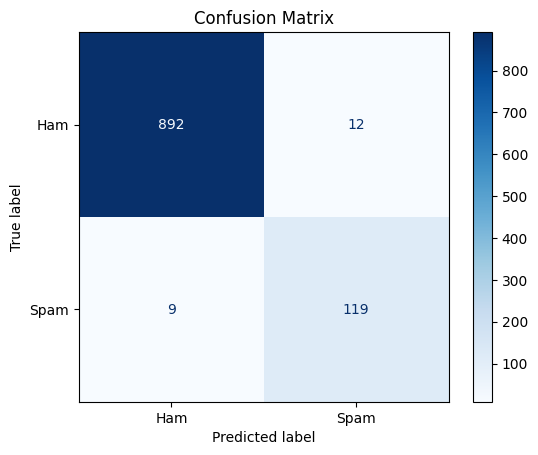

Confusion matrix [ [TN, FP], [FN, TP] ]:
[[892  12]
 [  9 119]]


In [6]:
print(classification_report(
    y_test, y_pred, target_names=["Ham", "Spam"], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Ham", "Spam"], cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_test, y_pred))

## 6. Try the classifier on new messages

The probability is the model's estimated spam score. It is not a guarantee that a message is safe or malicious.

In [7]:
def predict_spam(message):
    """Return the predicted class and estimated spam probability for one SMS."""
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please provide a non-empty text message.")
    probability = float(model.predict_proba([message])[0, 1])
    label = "spam" if probability >= 0.5 else "ham"
    return {"prediction": label, "spam_probability": round(probability, 4)}

examples = [
    "Hey, are we still meeting tomorrow after class?",
    "Congratulations! You have won a free prize. Call now to claim."
]
for example in examples:
    print(example)
    print(predict_spam(example), "\n")

Hey, are we still meeting tomorrow after class?
{'prediction': 'ham', 'spam_probability': 0.0594} 

Congratulations! You have won a free prize. Call now to claim.
{'prediction': 'spam', 'spam_probability': 0.978} 



## 7. Save the trained model

The saved pipeline includes both TF-IDF vectorization and Logistic Regression. The Streamlit app loads this same file.

In [8]:
joblib.dump(model, "spam_classifier_model.joblib")
print("Saved: spam_classifier_model.joblib")

Saved: spam_classifier_model.joblib


## 8. Conclusion and limitations

- This project uses a real, labelled SMS corpus from the UCI Machine Learning Repository.
- TF-IDF + Logistic Regression provides a compact and interpretable baseline for text classification.
- The reported results apply to this one stratified hold-out split, not every SMS population.
- Spam patterns change over time; messages can be misclassified. Avoid clicking links or sharing personal information based only on this prediction.
- A stronger evaluation could use repeated stratified cross-validation and an external, newer SMS dataset.